# R · Kriging vs DiceKriging and RobustGaSP

**Idea.** libKriging's `Kriging` follows DiceKriging: at the same hyperparameters it
must give DiceKriging's numbers, and its default fit must be as accurate as the R
references.

**Reference.** DiceKriging (exact equality) and RobustGaSP (accuracy, cost).

**Tags.** class: Kriging · kernel: gauss, exp, matern3_2, matern5_2 ·
compared to: DiceKriging, RobustGaSP

DiceKriging is the reference implementation libKriging's `Kriging` follows
(same product-form kernels and range parametrization, same concentrated
likelihood). Hence two levels of comparison:

1. **Same hyperparameters → same numbers** (error-level): the concentrated
   log-likelihood at a given θ (`DiceKriging::logLikFun` vs
   `logLikelihoodFun`), and the universal kriging mean / stdev at fixed
   (θ, σ², β) (`predict(type = "UK")`).
2. **Default fits** on the shared datasets of `data/` (Branin, Hartmann 3,
   Borehole), with RobustGaSP as a third package: Q², fit time
   (warn-level comparisons).

## Installing DiceKriging and RobustGaSP

From CRAN (the configured repository, else cloud.r-project.org), into the
first library of `.libPaths()`, unless already installed. DiceKriging is
required; without RobustGaSP its comparison is skipped (warn-level).

In [1]:
repos <- getOption("repos")
if (is.null(repos) || any(repos == "@CRAN@")) repos <- c(CRAN = "https://cloud.r-project.org")
for (p in c("DiceKriging", "RobustGaSP")) {
  if (!requireNamespace(p, quietly = TRUE)) {
    message("installing ", p)
    tryCatch(install.packages(p, repos = repos, lib = .libPaths()[1]),
             error = function(e) message(p, " could not be installed: ", conditionMessage(e)))
  }
}

installing DiceKriging



installing RobustGaSP



also installing the dependencies ‘nloptr’, ‘RcppEigen’




In [2]:
suppressPackageStartupMessages({
  library(rlibkriging)
  library(DiceKriging)
})
has_rgasp <- requireNamespace("RobustGaSP", quietly = TRUE)
source("tools/R/gallery.R")
s <- suite("vs-DiceKriging-RobustGaSP_Kriging_R")
cat("rlibkriging", as.character(packageVersion("rlibkriging")), "| DiceKriging", as.character(packageVersion("DiceKriging")),
    "| RobustGaSP", if (has_rgasp) as.character(packageVersion("RobustGaSP")) else "absent", "\n")
DATASETS <- c("branin", "hartmann3", "borehole")

restoring definition of class “WarpKriging”



rlibkriging 1.2.2 | DiceKriging 1.6.1 | RobustGaSP 0.6.8 


## 1. Same hyperparameters, same numbers

In [3]:
for (name in DATASETS) {
  X <- read_data(name, "X"); y <- as.numeric(read_data(name, "y")); Xt <- read_data(name, "Xt")
  d <- ncol(X)
  colnames(X) <- colnames(Xt) <- paste0("x", 1:d)
  for (kernel in c("gauss", "matern5_2", "matern3_2", "exp")) {
    theta <- seq(0.2, 0.6, length.out = d)
    k <- Kriging(y, X, kernel, optim = "none", parameters = list(theta = matrix(theta, nrow = 1), is_theta_estim = FALSE))
    km0 <- km(~1, design = data.frame(X), response = y, covtype = kernel, coef.cov = theta,
              coef.var = k$sigma2(), coef.trend = as.numeric(k$beta()), control = list(trace = FALSE))
    # concentrated log-likelihood at theta (DiceKriging profiles sigma2 and beta the same way)
    km_fit <- km(~1, design = data.frame(X), response = y, covtype = kernel, control = list(trace = FALSE))
    ll_dk <- DiceKriging::logLikFun(theta, km_fit)
    ll_lk <- logLikelihoodFun(k, matrix(theta, nrow = 1))$logLikelihood
    check_close(s, sprintf("%s/%s: logLikelihood == DiceKriging logLikFun", name, kernel), ll_lk, ll_dk, rtol = 1e-8)
    p_dk <- predict(km0, newdata = data.frame(Xt), type = "UK", checkNames = FALSE)
    p_lk <- predict(k, Xt, return_stdev = TRUE)
    check_close(s, sprintf("%s/%s: UK mean == DiceKriging", name, kernel), p_lk$mean, p_dk$mean, rtol = 1e-6, atol = 1e-8 * sd(y))
    check_close(s, sprintf("%s/%s: UK stdev == DiceKriging", name, kernel), p_lk$stdev, p_dk$sd, rtol = 1e-5, atol = 1e-8 * sd(y))
  }
}

## 2. Default fits

The upper bounds of the range parameters are 73.09321 74.21277 
The initial values of range parameters are 1.461864 1.484255 
Start of the optimization  1  : 
The number of iterations is  34 
 The value of the  marginal posterior  function is  -96.79716 
 Optimized range parameters are 1.658536 5.32724 
 Optimized nugget parameter is 0 
 Convergence:  FALSE 
The initial values of range parameters are 0.1518717 0.1541979 
Start of the optimization  2  : 
The number of iterations is  17 
 The value of the  marginal posterior  function is  -96.79716 
 Optimized range parameters are 1.658499 5.327139 
 Optimized nugget parameter is 0 
 Convergence:  TRUE 
The upper bounds of the range parameters are 76.11197 76.73012 74.94479 
The initial values of range parameters are 1.522239 1.534602 1.498896 
Start of the optimization  1  : 
The number of iterations is  14 
 The value of the  marginal posterior  function is  -41.87276 
 Optimized range parameters are 1.565643 0.4318266 0.2651772 
 Opti

    dataset q2.rlibkriging fit_s.rlibkriging q2.rlibkriging BFGS10
1    branin      0.9990362       0.001707077             0.9990362
5 hartmann3      0.9767276       0.005708456             0.9767278
9  borehole      0.9990984       0.007958174             0.9990984
  fit_s.rlibkriging BFGS10 q2.DiceKriging fit_s.DiceKriging q2.RobustGaSP
1              0.008450747      0.9954188        0.01114702     0.9995904
5              0.054565668      0.9767279        0.01914573     0.9763451
9              0.084655046      0.9931095        0.04040599     0.9997825
  fit_s.RobustGaSP
1       0.01443505
5       0.01452684
9       0.12958646


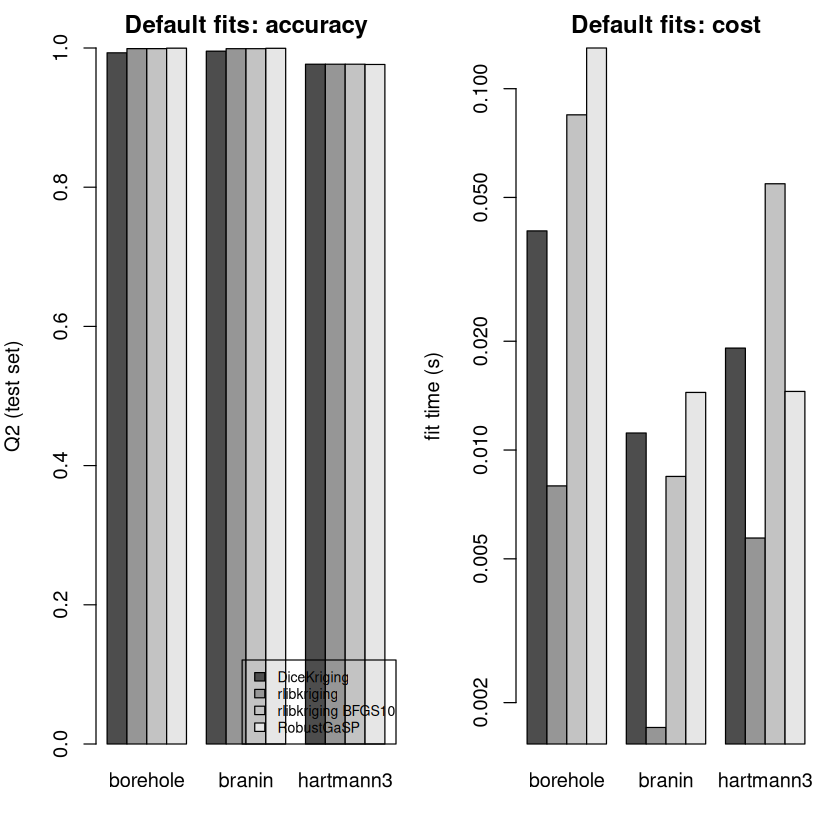

In [4]:
results <- list()
for (name in DATASETS) {
  X <- read_data(name, "X"); y <- as.numeric(read_data(name, "y")); Xt <- read_data(name, "Xt"); yt <- as.numeric(read_data(name, "yt"))
  colnames(X) <- colnames(Xt) <- paste0("x", 1:ncol(X))
  fits <- list(
    rlibkriging = function() { k <- Kriging(y, X, "matern5_2"); function(Z) predict(k, Z)$mean },
    `rlibkriging BFGS10` = function() { k <- Kriging(y, X, "matern5_2", optim = "BFGS10"); function(Z) predict(k, Z)$mean },
    DiceKriging = function() {
      m <- km(~1, design = data.frame(X), response = y, covtype = "matern5_2", control = list(trace = FALSE))
      function(Z) predict(m, newdata = data.frame(Z), type = "UK", checkNames = FALSE)$mean
    })
  if (has_rgasp) fits$RobustGaSP <- function() {
    m <- RobustGaSP::rgasp(design = X, response = y, kernel_type = "matern_5_2")
    function(Z) RobustGaSP::predict(m, Z)$mean
  }
  for (pkg in names(fits)) {
    t0 <- Sys.time()
    r <- tryCatch(fits[[pkg]](), error = function(e) e)
    t_fit <- as.numeric(difftime(Sys.time(), t0, units = "secs"))
    if (inherits(r, "error")) {
      if (startsWith(pkg, "rlibkriging")) check(s, paste0(name, "/", pkg, ": fit"), FALSE, detail = conditionMessage(r))
      next
    }
    m <- as.numeric(r(Xt))
    metric(s, name, pkg, q2 = q2(yt, m), rmse = rmse(yt, m), fit_s = t_fit)
    results[[length(results) + 1]] <- data.frame(dataset = name, package = pkg, q2 = q2(yt, m), fit_s = t_fit)
  }
}
res <- do.call(rbind, results)
print(reshape(res[, c("dataset", "package", "q2", "fit_s")], idvar = "dataset", timevar = "package", direction = "wide"))
op <- par(mfrow = c(1, 2), mar = c(4, 4, 2, 1))
q <- tapply(res$q2, list(res$package, res$dataset), mean)
barplot(pmax(q, 0), beside = TRUE, legend.text = rownames(q), args.legend = list(x = "bottomright", cex = .7),
        ylim = c(0, 1), ylab = "Q2 (test set)", main = "Default fits: accuracy")
t <- tapply(res$fit_s, list(res$package, res$dataset), mean)
barplot(t, beside = TRUE, log = "y", ylab = "fit time (s)", main = "Default fits: cost")
par(op)

In [5]:
for (name in DATASETS) {
  r <- res[res$dataset == name, ]
  best_other <- max(r$q2[!startsWith(r$package, "rlibkriging")])
  check_greater(s, paste0(name, ": Q2(rlibkriging) - best other package"), r$q2[r$package == "rlibkriging"] - best_other, -0.02, severity = "warn")
  check_greater(s, paste0(name, ": Q2(rlibkriging BFGS10) > 0.9"), r$q2[r$package == "rlibkriging BFGS10"], 0.9)
}

## Summary

The metrics of this notebook, the number of checks per status, and every check that
did not pass (FAIL: error-level, fails the run; WARN: warn-level; KNOWN: listed in
`tools/known_issues.csv`, with its issue; SKIP: feature absent from the installed version).
All of them are also written to `results/vs-DiceKriging-RobustGaSP_Kriging_R.checks.csv` and `.metrics.csv`.

In [6]:
suite_summary(s)

      case            package value.q2 value.rmse value.fit_s
    branin        rlibkriging 0.999036   1.704110  0.00170708
    branin rlibkriging BFGS10 0.999036   1.704140  0.00845075
    branin        DiceKriging 0.995419   3.715310  0.01114700
    branin         RobustGaSP 0.999590   1.110880  0.01443510
 hartmann3        rlibkriging 0.976728   0.135281  0.00570846
 hartmann3 rlibkriging BFGS10 0.976728   0.135280  0.05456570
 hartmann3        DiceKriging 0.976728   0.135280  0.01914570
 hartmann3         RobustGaSP 0.976345   0.136388  0.01452680
  borehole        rlibkriging 0.999098   1.357170  0.00795817
  borehole rlibkriging BFGS10 0.999098   1.357170  0.08465500
  borehole        DiceKriging 0.993110   3.751920  0.04040600
  borehole         RobustGaSP 0.999782   0.666626  0.12958600

 PASS  FAIL  WARN KNOWN  SKIP 
   42     0     0     0     0 


In [7]:
suite_finalize(s)


 PASS  FAIL  WARN KNOWN  SKIP 
   42     0     0     0     0 
